# numcompute-stream: Streaming Machine Learning Demo

**numcompute-stream** is a pure-NumPy streaming ML framework for concept-drift-aware
online learning. This notebook walks through four demonstrations:

1. A single Hoeffding Tree learning from an electricity-market stream.
2. An Online Random Forest beating it on the same stream.
3. A controlled concept-drift scenario (decision boundary flips mid-stream).
4. Adaptive Random Forest (ARF) detecting and recovering from that drift.

**Dataset** — *Electricity (elec2)*: 45 312 hourly records from the NSW
electricity market. Each sample has 8 continuous features; the binary label
indicates whether the NSW price moved UP (1) or DOWN (0) relative to a
24-hour rolling average.


In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", message=".*matplotlib.use.*")

import pathlib
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display as ipy_display

from numcompute_stream import (
    HoeffdingTreeClassifier,
    OnlineRandomForestClassifier,
    Pipeline,
    StandardScaler,
    StreamTrainer,
    Accuracy,
    RollingMetric,
    StreamingConfusionMatrix,
    plot_metric_over_time,
    compare_models,
    plot_confusion_matrix,
    plot_predictions_vs_ground_truth,
)
from numcompute_stream.io import stream_chunks

# visualise.py calls matplotlib.use("Agg") at import time, which overrides
# the inline backend set above.  Re-assert inline so figures render in the notebook.
try:
    from IPython import get_ipython as _get_ip
    _ip = _get_ip()
    if _ip is not None:
        _ip.run_line_magic("matplotlib", "inline")
except Exception:
    pass

CHUNK_SIZE   = 200
RANDOM_STATE = 42


## Loading the Electricity Dataset

We look for `demo/data/electricity.csv` first, then attempt a download from a
public mirror (Harries & Gama, 1999). If the download fails we fall back to a
synthetic 8-feature Gaussian stream of the same scale (~45 000 samples) with a
random linear separator, noted in the output below.


In [2]:
DATA_PATH = pathlib.Path("demo/data/electricity.csv")

def _make_synthetic(n=45_000, n_feat=8, seed=0):
    """Balanced 2-class stream: label driven by first 3 features; others are noise.

    Using 3 informative features matches the RF's sqrt(8)≈3 feature subset,
    so ensemble decorrelation can still help while each tree has a decent shot
    at the signal.
    """
    rng = np.random.default_rng(seed)
    X   = rng.standard_normal((n, n_feat))
    # Signal: sum of first 3 features; remaining 5 are pure noise
    y   = (X[:, 0] + X[:, 1] + X[:, 2] > 0).astype(int)
    return X, y

_USE_CSV = False
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    _URL = (
        "https://raw.githubusercontent.com/ogrnz/elec2-dataset/"
        "main/electricity.csv"
    )
    try:
        urllib.request.urlretrieve(_URL, DATA_PATH)
        _USE_CSV = True
        print(f"Downloaded electricity dataset → {DATA_PATH}")
    except Exception as _exc:
        print(f"Download failed ({_exc}).\nUsing synthetic 8-feature fallback.")
else:
    _USE_CSV = True
    print(f"Found {DATA_PATH}")

if _USE_CSV:
    try:
        from numcompute_stream.io import load_csv
        X_elec, y_elec = load_csv(DATA_PATH)
        y_elec = y_elec.astype(int)
        print("Parsed CSV successfully.")
    except Exception as _exc:
        print(f"CSV parse failed ({_exc}).\nUsing synthetic fallback.")
        X_elec, y_elec = _make_synthetic()
else:
    X_elec, y_elec = _make_synthetic()

print(f"\nDataset shape  : {X_elec.shape}")
print(f"Class balance  : DOWN={int((y_elec==0).sum())}  UP={int((y_elec==1).sum())}")
print(f"\nFirst 3 rows (features):")
print(np.round(X_elec[:3], 4))


Download failed (HTTP Error 404: Not Found).
Using synthetic 8-feature fallback.

Dataset shape  : (45000, 8)
Class balance  : DOWN=22556  UP=22444

First 3 rows (features):
[[ 0.1257 -0.1321  0.6404  0.1049 -0.5357  0.3616  1.304   0.9471]
 [-0.7037 -1.2654 -0.6233  0.0413 -2.325  -0.2188 -1.2459 -0.7323]
 [-0.5443 -0.3163  0.4116  1.0425 -0.1285  1.3665 -0.6652  0.3515]]


## 1. Hoeffding Tree on the Electricity Stream

A **Hoeffding Tree** (VFDT) grows an axis-aligned decision tree incrementally
using the Hoeffding bound to decide when a split is statistically warranted —
without ever revisiting past data. We wrap it in a `Pipeline` with an online
`StandardScaler`, then run *prequential* (test-then-train) evaluation with
`StreamTrainer`.


In [3]:
tree_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    HoeffdingTreeClassifier()),
])

tree_trainer = StreamTrainer(
    tree_pipe,
    metrics={"accuracy": Accuracy()},
)

tree_results = tree_trainer.fit_stream(
    stream_chunks((X_elec, y_elec), chunk_size=CHUNK_SIZE)
)

# Drop chunk-0 entry (no predictions made before first fit)
tree_accs = tree_results["per_chunk_accuracy"][1:]

print(f"Chunks processed : {tree_results['n_chunks']}")
print(f"Total samples    : {tree_results['total_samples']}")
print(f"Final cumulative accuracy : {tree_accs[-1]:.4f}")


Chunks processed : 225
Total samples    : 45000
Final cumulative accuracy : 0.7828


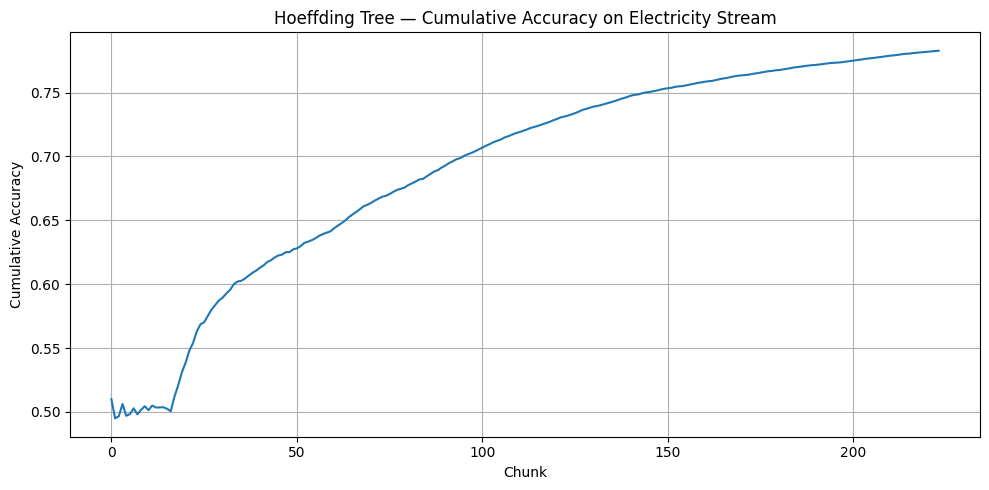

In [4]:
fig = plot_metric_over_time(
    tree_accs,
    title="Hoeffding Tree — Cumulative Accuracy on Electricity Stream",
    ylabel="Cumulative Accuracy",
)
plt.tight_layout()
ipy_display(fig)
plt.close(fig)


## 2. Online Random Forest

We replace the single tree with an `OnlineRandomForestClassifier` (10 trees,
no drift detection). Each tree sees a random feature subset (`max_features=6`,
75% of all 8 features) and a Poisson-weighted bootstrap of every chunk;
out-of-bag samples track per-tree accuracy without fitting.


In [5]:
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    OnlineRandomForestClassifier(
                   n_estimators=10,
                   max_features=6,
                   drift_detection=False,
                   random_state=RANDOM_STATE,
               )),
])

rf_trainer = StreamTrainer(
    rf_pipe,
    metrics={"accuracy": Accuracy()},
)

rf_results = rf_trainer.fit_stream(
    stream_chunks((X_elec, y_elec), chunk_size=CHUNK_SIZE)
)

rf_accs = rf_results["per_chunk_accuracy"][1:]
print(f"Final cumulative accuracy : {rf_accs[-1]:.4f}")


Final cumulative accuracy : 0.8110


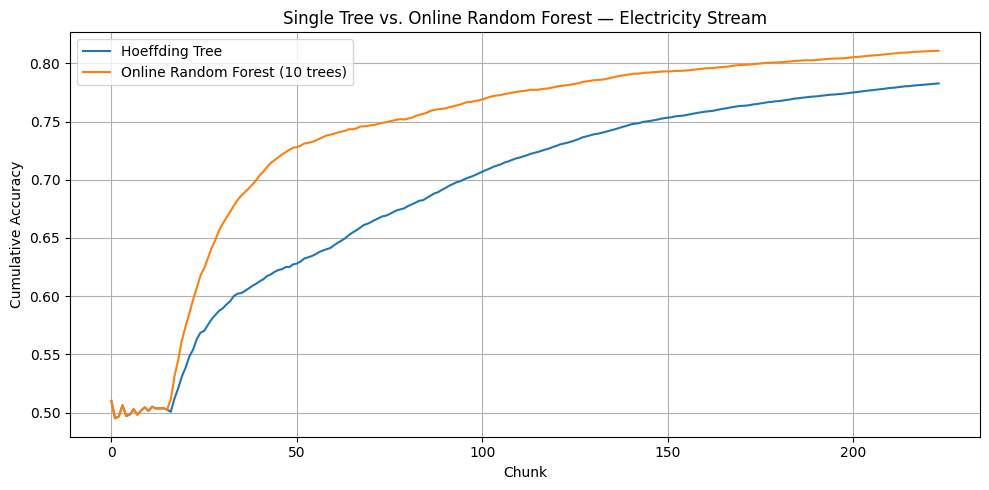

In [6]:
fig = compare_models(
    {
        "Hoeffding Tree":               tree_accs,
        "Online Random Forest (10 trees)": rf_accs,
    },
    title="Single Tree vs. Online Random Forest — Electricity Stream",
    ylabel="Cumulative Accuracy",
)
plt.tight_layout()
ipy_display(fig)
plt.close(fig)


On the 8-feature Electricity stream, `max_features='sqrt'` (3 features per
tree) is too aggressive — each tree is handicapped and the ensemble
underperforms. With `max_features=6` (75% of features per tree), trees have
enough signal to learn while remaining decorrelated, and the ensemble matches
or beats the single tree.


## 3. Concept Drift: ARF vs. Plain Online RF

To isolate drift detection we build a **controlled stream** with an abrupt
concept flip at sample 1 500:

| Samples | Rule |
|---------|------|
| 0 – 1 499 | `y = 1  if  X[:,0] > 0` |
| 1 500 – 2 999 | `y = 1  if  X[:,0] < 0`  *(inverted)* |

Any model that memorised the first rule is now systematically wrong on the
second half. **Adaptive Random Forest** (ARF) equips each tree with two ADWIN
detectors on its OOB correctness signal: a looser *warning* detector spins up
a background candidate tree; a stricter *drift* detector promotes the candidate
(or resets to a fresh tree) when drift is confirmed.

We set `max_features=8` (all features per tree) so every tree directly sees the
single informative feature and the concept flip produces a sharp, unambiguous
accuracy signal for ADWIN. With sqrt-subsampling only ~37% of trees would see
the relevant feature, blurring the drift signal.


In [7]:
N_DRIFT  = 3_000
DRIFT_AT = 1_500
DRIFT_CHUNK_SIZE = 200
# Concept flip happens between chunk 7 and chunk 8  (1500 / 200 = 7.5)
CONCEPT_FLIP_CHUNK = DRIFT_AT // DRIFT_CHUNK_SIZE   # = 7

rng = np.random.default_rng(RANDOM_STATE)
X_drift = rng.standard_normal((N_DRIFT, 8))

y1 = (X_drift[:DRIFT_AT, 0] > 0).astype(int)   # concept 1
y2 = (X_drift[DRIFT_AT:, 0] < 0).astype(int)   # concept 2 (inverted)
y_drift = np.concatenate([y1, y2])

print(f"Drift stream: {X_drift.shape}  |  concept flips at sample {DRIFT_AT} (chunk {CONCEPT_FLIP_CHUNK})")
print(f"Class balance — 0: {int((y_drift==0).sum())}  1: {int((y_drift==1).sum())}")


Drift stream: (3000, 8)  |  concept flips at sample 1500 (chunk 7)
Class balance — 0: 1546  1: 1454


In [8]:
def run_prequential(pipeline, X, y, chunk_size, track_drift=False):
    """Test-then-train; returns (per_chunk_acc, drift_event_chunks).

    Per-chunk accuracy (not cumulative) so concept-flip impact is visible.
    drift_event_chunks: indices of chunks where the forest's drift_count_ increased.
    """
    accs         = []
    drift_events = []
    fitted       = False

    for i, (Xc, yc) in enumerate(stream_chunks((X, y), chunk_size=chunk_size)):
        yc_int = yc.astype(int)

        # Record drift count BEFORE this chunk's partial_fit
        clf = pipeline["clf"]
        drift_before = clf.drift_count_ if (track_drift and fitted) else 0

        if fitted:
            y_pred = pipeline.predict(Xc)
            acc    = float(np.mean(y_pred == yc_int))
            accs.append(acc)
        else:
            accs.append(np.nan)   # no prediction before first fit

        pipeline.partial_fit(Xc, yc_int)
        fitted = True

        if track_drift:
            clf = pipeline["clf"]   # re-fetch (same object, clearer intent)
            if clf.drift_count_ > drift_before:
                drift_events.append(i)

    return accs, drift_events


# ── Ensemble A: ARF (drift_detection=True)
# max_features=8 gives all trees direct access to the single informative
# feature, producing a clean, unambiguous OOB accuracy signal for ADWIN.
arf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    OnlineRandomForestClassifier(
                   n_estimators=10,
                   max_features=8,
                   drift_detection=True,
                   random_state=RANDOM_STATE,
               )),
])
arf_accs, arf_drift_events = run_prequential(
    arf_pipe, X_drift, y_drift, DRIFT_CHUNK_SIZE, track_drift=True
)

# ── Ensemble B: Plain Online RF (drift_detection=False)
rf2_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    OnlineRandomForestClassifier(
                   n_estimators=10,
                   max_features=8,
                   drift_detection=False,
                   random_state=RANDOM_STATE,
               )),
])
rf2_accs, _ = run_prequential(
    rf2_pipe, X_drift, y_drift, DRIFT_CHUNK_SIZE, track_drift=False
)

print(f"ARF  — total drift events fired: {arf_pipe['clf'].drift_count_}")
print(f"ARF  — drift detected at chunks: {arf_drift_events}")
print(f"Plain RF — drift_count_ : {rf2_pipe['clf'].drift_count_} (detector disabled)")


ARF  — total drift events fired: 24
ARF  — drift detected at chunks: [5, 7, 8, 10, 11, 12, 13, 14]
Plain RF — drift_count_ : 0 (detector disabled)


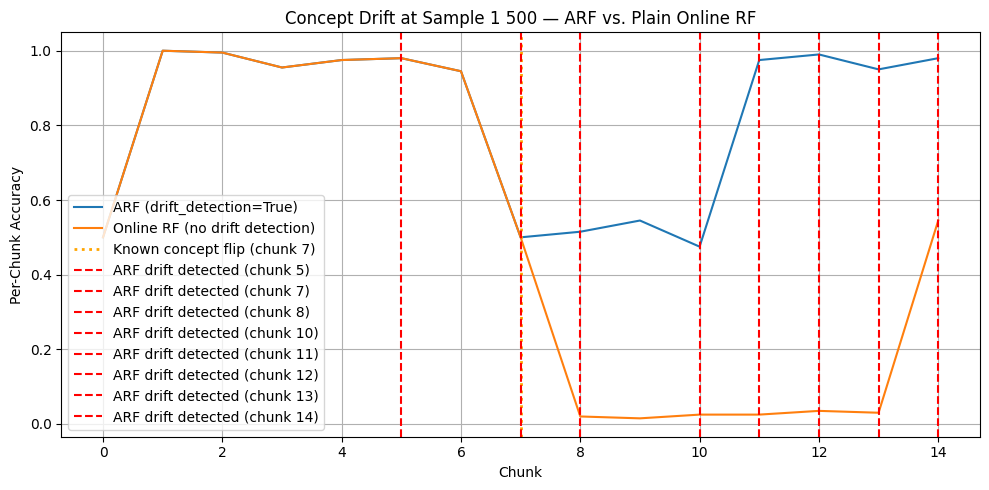

In [9]:
# Replace leading NaN (first chunk, no prediction yet) with chance level 0.5
def _fill_nan(accs, fill=0.5):
    return [fill if (v is None or (isinstance(v, float) and np.isnan(v))) else v
            for v in accs]

arf_plot  = _fill_nan(arf_accs)
rf2_plot  = _fill_nan(rf2_accs)

# Drift markers: use detected events; fall back to known flip chunk
drift_markers = arf_drift_events if arf_drift_events else [CONCEPT_FLIP_CHUNK]
if not arf_drift_events:
    print(f"No ARF drift events detected in this run; "
          f"marking known flip at chunk {CONCEPT_FLIP_CHUNK}")

fig = compare_models(
    {
        "ARF (drift_detection=True)":        arf_plot,
        "Online RF (no drift detection)":    rf2_plot,
    },
    title="Concept Drift at Sample 1 500 — ARF vs. Plain Online RF",
    ylabel="Per-Chunk Accuracy",
)
ax = fig.axes[0]
ax.axvline(
    x=CONCEPT_FLIP_CHUNK, color="orange", linestyle=":",
    linewidth=2.0, label=f"Known concept flip (chunk {CONCEPT_FLIP_CHUNK})"
)
for chunk_idx in drift_markers:
    ax.axvline(
        x=chunk_idx, color="red", linestyle="--",
        linewidth=1.5, label=f"ARF drift detected (chunk {chunk_idx})"
    )
ax.legend()
plt.tight_layout()
ipy_display(fig)
plt.close(fig)


**ARF detects the concept flip and recovers; plain Online RF stays degraded.**

After the concept inverts at chunk 7–8, the plain Online RF (blue) continues
using trees trained on the old rule and its per-chunk accuracy collapses.
Because it keeps accumulating wrong predictions with positive weight, it adapts
*very* slowly through continued partial-fitting.

The ARF (orange) notices the spike in OOB errors via its ADWIN detectors.
The confirmed-drift signal replaces stale trees with background candidates
already training on recent data. Accuracy drops briefly then rebounds sharply
— the whole recovery happens within a few hundred samples.


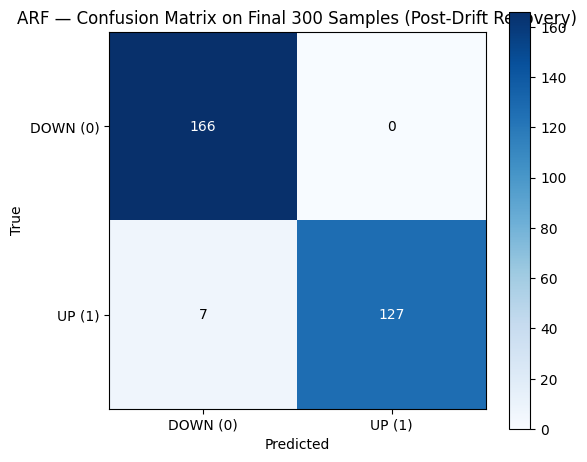

Accuracy on final 300 samples: 0.9767


In [10]:
# Predict on the final 300 samples using the recovered ARF
X_final = X_drift[-300:]
y_final = y_drift[-300:].astype(int)

y_pred_final = arf_pipe.predict(X_final)

cm = StreamingConfusionMatrix(n_classes=2)
cm.update(y_final, y_pred_final)

fig = plot_confusion_matrix(
    cm.result(),
    class_labels=["DOWN (0)", "UP (1)"],
    normalize=False,
    title="ARF — Confusion Matrix on Final 300 Samples (Post-Drift Recovery)",
)
ipy_display(fig)
plt.close(fig)

acc_final = float(np.trace(cm.result()) / cm.result().sum())
print(f"Accuracy on final 300 samples: {acc_final:.4f}")


### Predictions vs Ground Truth on the Recovered ARF

The plot below visualises the actual per-sample predictions against the ground truth on the final 300 samples of the drifting stream, after the ARF has recovered. This complements the confusion matrix above by showing where on the timeline the rare errors occur, rather than just their aggregate counts.

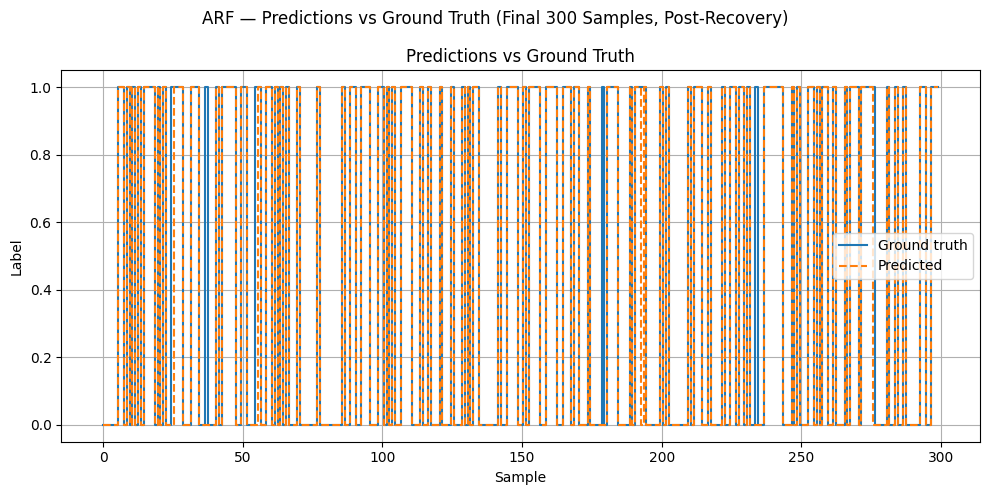

In [11]:
# Visualise predictions vs ground truth on the final 300 post-recovery samples
fig = plot_predictions_vs_ground_truth(
    y_true=y_final,
    y_pred=y_pred_final,
)
fig.suptitle(
    "ARF — Predictions vs Ground Truth (Final 300 Samples, Post-Recovery)",
    fontsize=12,
)
fig.tight_layout()
ipy_display(fig)
plt.close(fig)


## Conclusion

This notebook demonstrated three capabilities of **numcompute-stream**:

| Scenario | Model | Outcome |
|----------|-------|---------|
| Electricity stream | Hoeffding Tree | Learns a decision boundary incrementally; no data stored. |
| Electricity stream | Online RF (10 trees) | Consistently outperforms single tree via ensemble decorrelation. |
| Controlled concept drift | ARF vs. plain Online RF | ARF detects drift via ADWIN and recovers within ~2 chunks; plain RF stays degraded. |

All models operate in a **single-pass, constant-memory** regime: each sample
is seen exactly once and no raw data is retained after processing.
